In [1]:
import kagglehub

path = kagglehub.dataset_download("crawford/gene-expression")
print(path)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\zehra\.cache\kagglehub\datasets\crawford\gene-expression\versions\3


In [2]:
from pathlib import Path

files = list(Path(path).rglob("*"))

for file in files:
    if file.is_file():
        print(file.name, "—", file.stat().st_size, "bytes")

actual.csv — 511 bytes
data_set_ALL_AML_independent.csv — 1860352 bytes
data_set_ALL_AML_train.csv — 2039681 bytes


In [3]:
import pandas as pd

data_path = Path(path)

train = pd.read_csv(data_path / "data_set_ALL_AML_train.csv")
test = pd.read_csv(data_path / "data_set_ALL_AML_independent.csv")
actual = pd.read_csv(data_path / "actual.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Labels:", actual.shape)

print("\nTrain columns:", train.columns[:10].tolist())
print("\nLabels preview:")
print(actual.head())

Train: (7129, 78)
Test: (7129, 70)
Labels: (72, 2)

Train columns: ['Gene Description', 'Gene Accession Number', '1', 'call', '2', 'call.1', '3', 'call.2', '4', 'call.3']

Labels preview:
   patient cancer
0        1    ALL
1        2    ALL
2        3    ALL
3        4    ALL
4        5    ALL


In [4]:
train_patients = [col for col in train.columns if col.isdigit()]
test_patients = [col for col in test.columns if col.isdigit()]

print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))

print("Train IDs:", train_patients)
print("Test IDs:", test_patients)

Training patients: 38
Test patients: 34
Train IDs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '34', '35', '36', '37', '38', '28', '29', '30', '31', '32', '33']
Test IDs: ['39', '40', '42', '47', '48', '49', '41', '43', '44', '45', '46', '70', '71', '72', '68', '69', '67', '55', '56', '59', '52', '53', '51', '50', '54', '57', '58', '60', '61', '65', '66', '63', '64', '62']


In [5]:
# Keep expression columns only
train_expr = train[train_patients].T
test_expr = test[test_patients].T


In [6]:
# Patient IDs as integers
train_expr.index = train_expr.index.astype(int)
test_expr.index = test_expr.index.astype(int)

In [7]:
# Encode ALL = 1, AML = 0
actual["cancer"] = actual["cancer"].map({"ALL": 1, "AML": 0})

In [8]:
# Attach labels using patient IDs
train_expr["target"] = actual.set_index("patient").loc[train_expr.index, "cancer"]
test_expr["target"] = actual.set_index("patient").loc[test_expr.index, "cancer"]

print("Train:", train_expr.shape)
print("Test:", test_expr.shape)
print("Train labels:", train_expr["target"].value_counts())
print("Test labels:", test_expr["target"].value_counts())

Train: (38, 7130)
Test: (34, 7130)
Train labels: target
1    27
0    11
Name: count, dtype: int64
Test labels: target
1    20
0    14
Name: count, dtype: int64


In [9]:
import numpy as np

X_train = train_expr.drop(columns="target")

print("Missing values in training data:", X_train.isna().sum().sum())
print("Infinite values in training data:",np.isinf(X_train.to_numpy(dtype=float)).sum())
print("Duplicate samples:", X_train.duplicated().sum())
print("Constant features:", (X_train.nunique() <= 1).sum())

Missing values in training data: 0
Infinite values in training data: 0


Duplicate samples: 0
Constant features: 0


In [10]:
print("Negative values:", (X_train < 0).sum().sum())
print("Zero values:", (X_train == 0).sum().sum())

print("Minimum:", X_train.min().min())
print("Maximum:", X_train.max().max())
print("Mean:", X_train.to_numpy().mean())
print("Median:", X_train.stack().median())

Negative values: 77175
Zero values: 738
Minimum: -28400
Maximum: 61228
Mean: 637.6980014913142
Median: 127.0


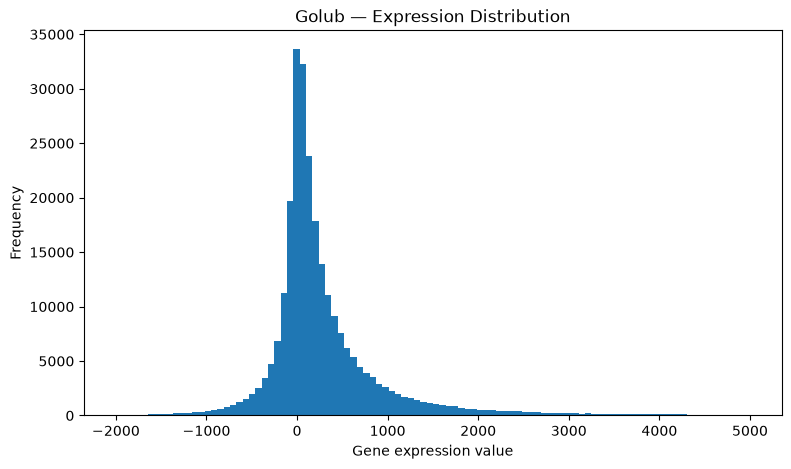

In [11]:
import matplotlib.pyplot as plt

values = X_train.to_numpy().flatten()

plt.figure(figsize=(9, 5))
plt.hist(values, bins=100, range=(-2000, 5000))
plt.xlabel("Gene expression value")
plt.ylabel("Frequency")
plt.title("Golub — Expression Distribution")
plt.show()

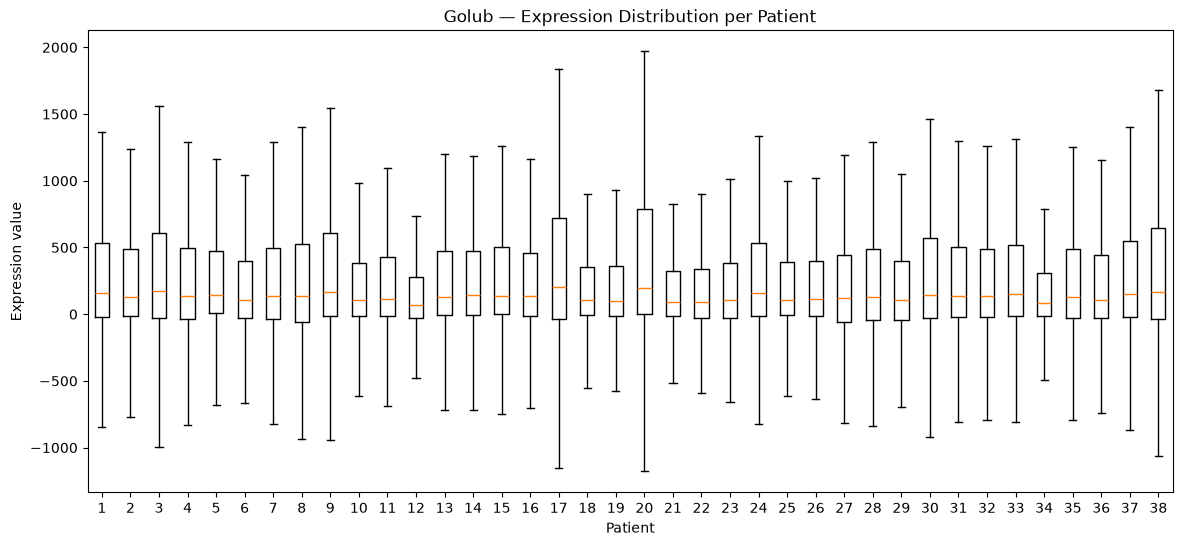

In [12]:
plt.figure(figsize=(14, 6))
plt.boxplot(X_train.T, showfliers=False)
plt.xlabel("Patient")
plt.ylabel("Expression value")
plt.title("Golub — Expression Distribution per Patient")
plt.show()

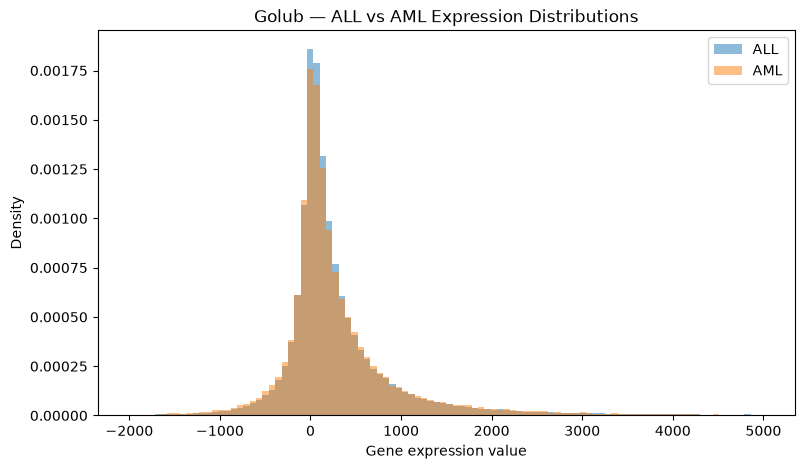

In [13]:
all_values = X_train.loc[train_expr["target"] == 1].to_numpy().flatten()
aml_values = X_train.loc[train_expr["target"] == 0].to_numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(all_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="ALL")

plt.hist(aml_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="AML")

plt.xlabel("Gene expression value")
plt.ylabel("Density")
plt.title("Golub — ALL vs AML Expression Distributions")
plt.legend()
plt.show()

In [14]:
gene_variances = X_train.var(axis=0)

print(gene_variances.describe())
print(gene_variances.nlargest(10))

count    7.129000e+03
mean     6.820928e+05
std      3.845060e+06
min      4.769018e+02
25%      8.210373e+03
50%      3.170128e+04
75%      1.295735e+05
max      1.609285e+08
dtype: float64
5709    1.609285e+08
5647    9.014333e+07
5506    6.822979e+07
6605    6.455910e+07
5710    6.425958e+07
18      5.694293e+07
5715    5.456498e+07
4016    4.963480e+07
5228    4.168747e+07
41      4.010845e+07
dtype: float64


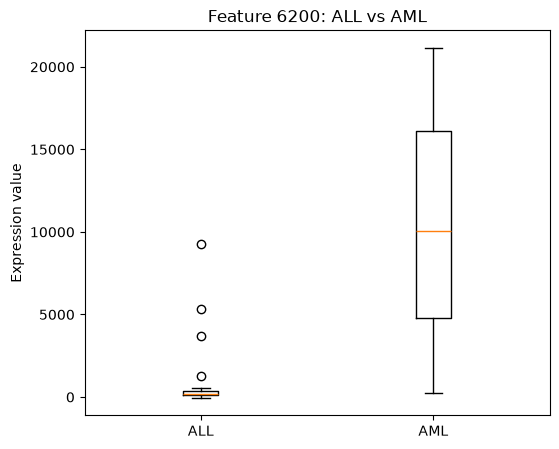

In [15]:
gene = 6200

all_expr = X_train.loc[train_expr["target"] == 1, gene]
aml_expr = X_train.loc[train_expr["target"] == 0, gene]

plt.figure(figsize=(6, 5))
plt.boxplot([all_expr, aml_expr], tick_labels=["ALL", "AML"])
plt.ylabel("Expression value")
plt.title(f"Feature {gene}: ALL vs AML")
plt.show()

In [16]:
all_means = X_train.loc[train_expr["target"] == 1].mean(axis=0)
aml_means = X_train.loc[train_expr["target"] == 0].mean(axis=0)

mean_differences = (all_means - aml_means).abs()

print(mean_differences.nlargest(20))

6200    9604.686869
1673    8952.720539
2185    7711.875421
1881    7279.101010
1375    6606.117845
2401    6546.434343
1393    6159.313131
6199    5943.760943
6802    5600.602694
4935    5531.602694
6805    5510.622896
4195    5465.912458
6796    5429.797980
5975    5221.582492
6612    5210.710438
1703    5041.451178
6605    4962.983165
6776    4812.410774
2344    4775.235690
6208    4757.050505
dtype: float64


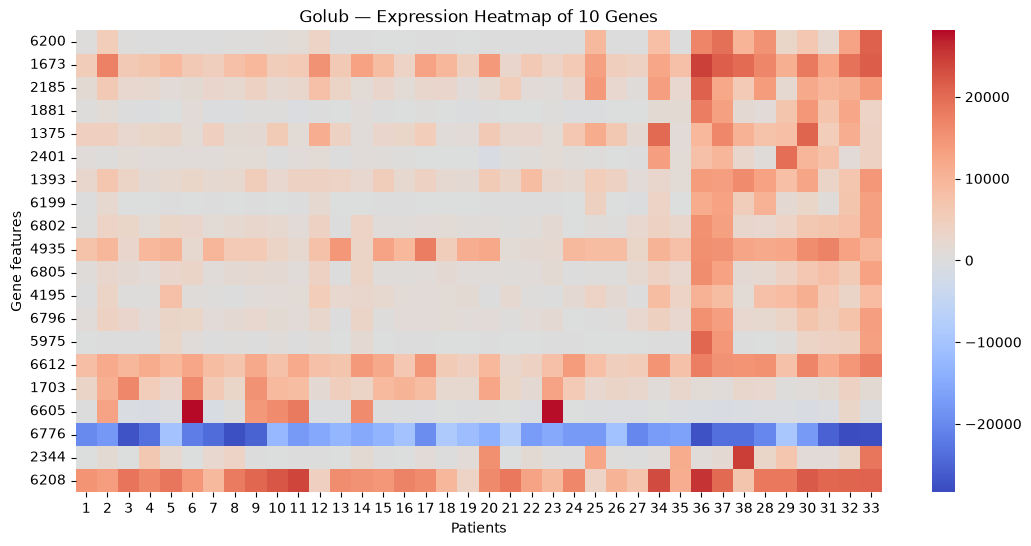

In [17]:
import seaborn as sns

top_genes = mean_differences.nlargest(20).index

heatmap_data = X_train[top_genes].T
plt.figure(figsize=(13, 6))

sns.heatmap(
heatmap_data, cmap="coolwarm", center=0
)

plt.xlabel("Patients")
plt.ylabel("Gene features")
plt.title("Golub — Expression Heatmap of 10 Genes")
plt.show()

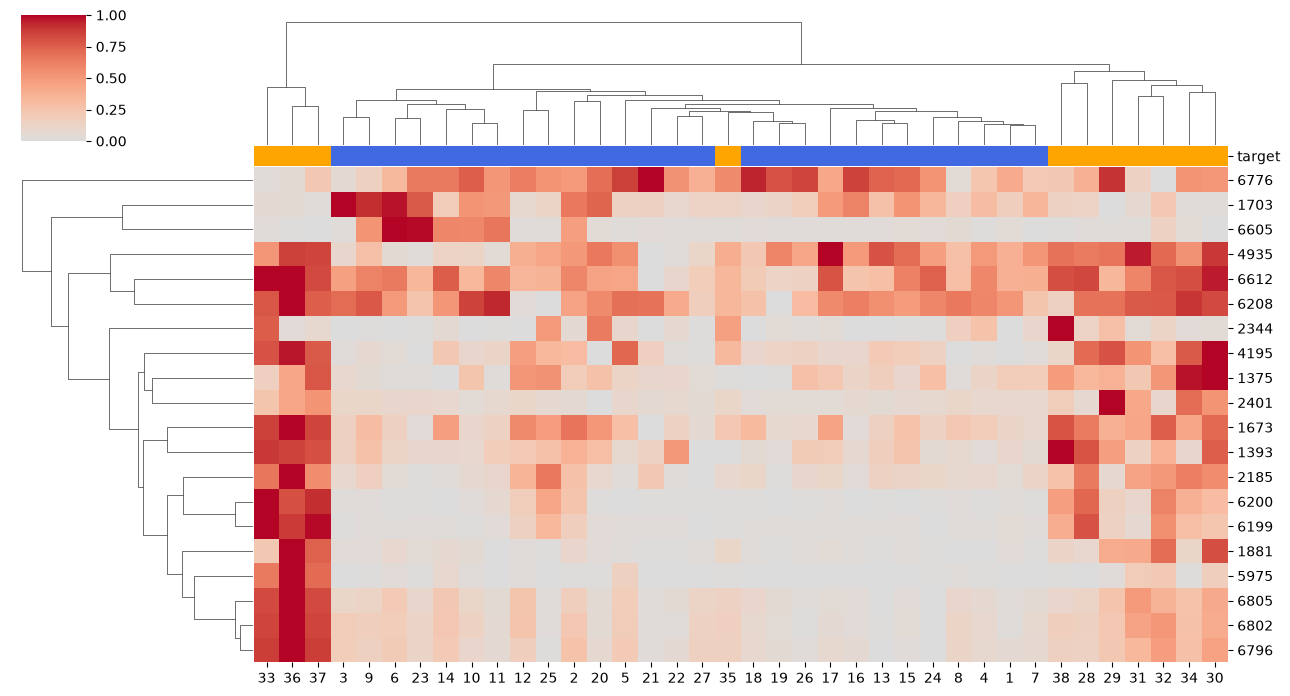

In [18]:
patient_colors = train_expr["target"].map({
    1: "royalblue",
    0: "orange"
})

sns.clustermap(
    heatmap_data,
    cmap="coolwarm",
    center=0,
    standard_scale=0,
    col_colors=patient_colors.loc[heatmap_data.columns],
    figsize=(13, 7)
)

plt.show()

In [19]:
X_train_log = np.sign(X_train) * np.log2(1 + np.abs(X_train))

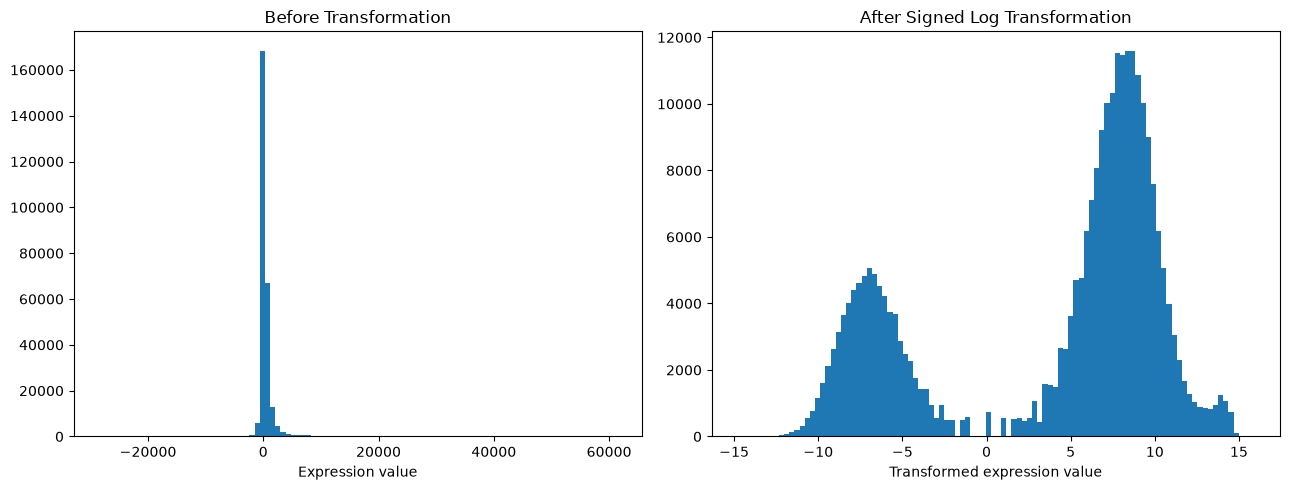

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(X_train.to_numpy().flatten(), bins=100)
axes[0].set_title("Before Transformation")
axes[0].set_xlabel("Expression value")

axes[1].hist(X_train_log.to_numpy().flatten(), bins=100)
axes[1].set_title("After Signed Log Transformation")
axes[1].set_xlabel("Transformed expression value")

plt.tight_layout()
plt.show()

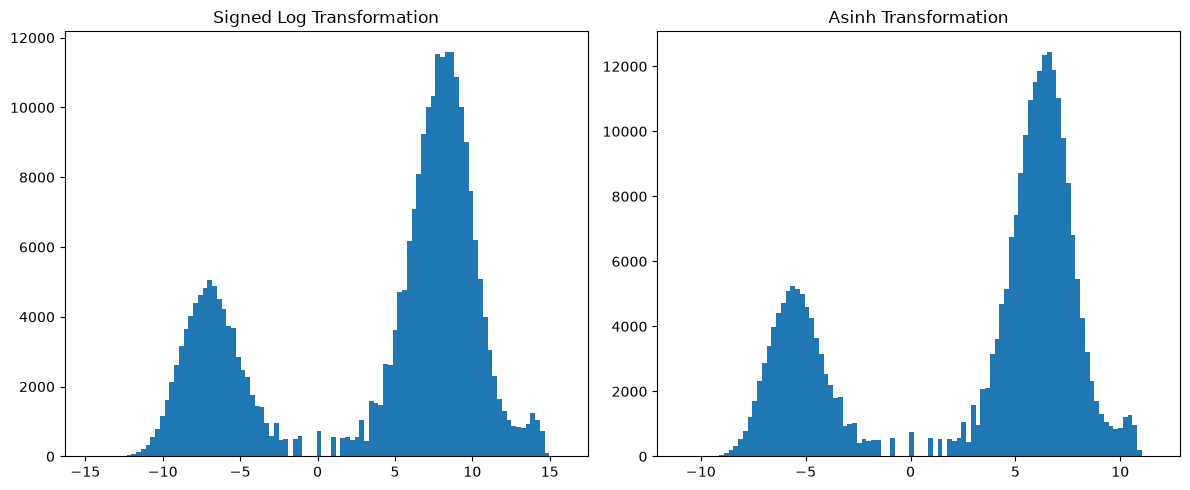

In [21]:
X_train_asinh = np.arcsinh(X_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(X_train_log.to_numpy().ravel(), bins=100)
axes[0].set_title("Signed Log Transformation")

axes[1].hist(X_train_asinh.to_numpy().ravel(), bins=100)
axes[1].set_title("Asinh Transformation")

plt.tight_layout()
plt.show()

In [30]:
all_data = X_train.loc[train_expr["target"] == 1]
aml_data = X_train.loc[train_expr["target"] == 0]

In [33]:
all_log = np.sign(all_data) * np.log1p(np.abs(all_data))
aml_log = np.sign(aml_data) * np.log1p(np.abs(aml_data))

all_asinh = np.arcsinh(all_data)
aml_asinh = np.arcsinh(aml_data)

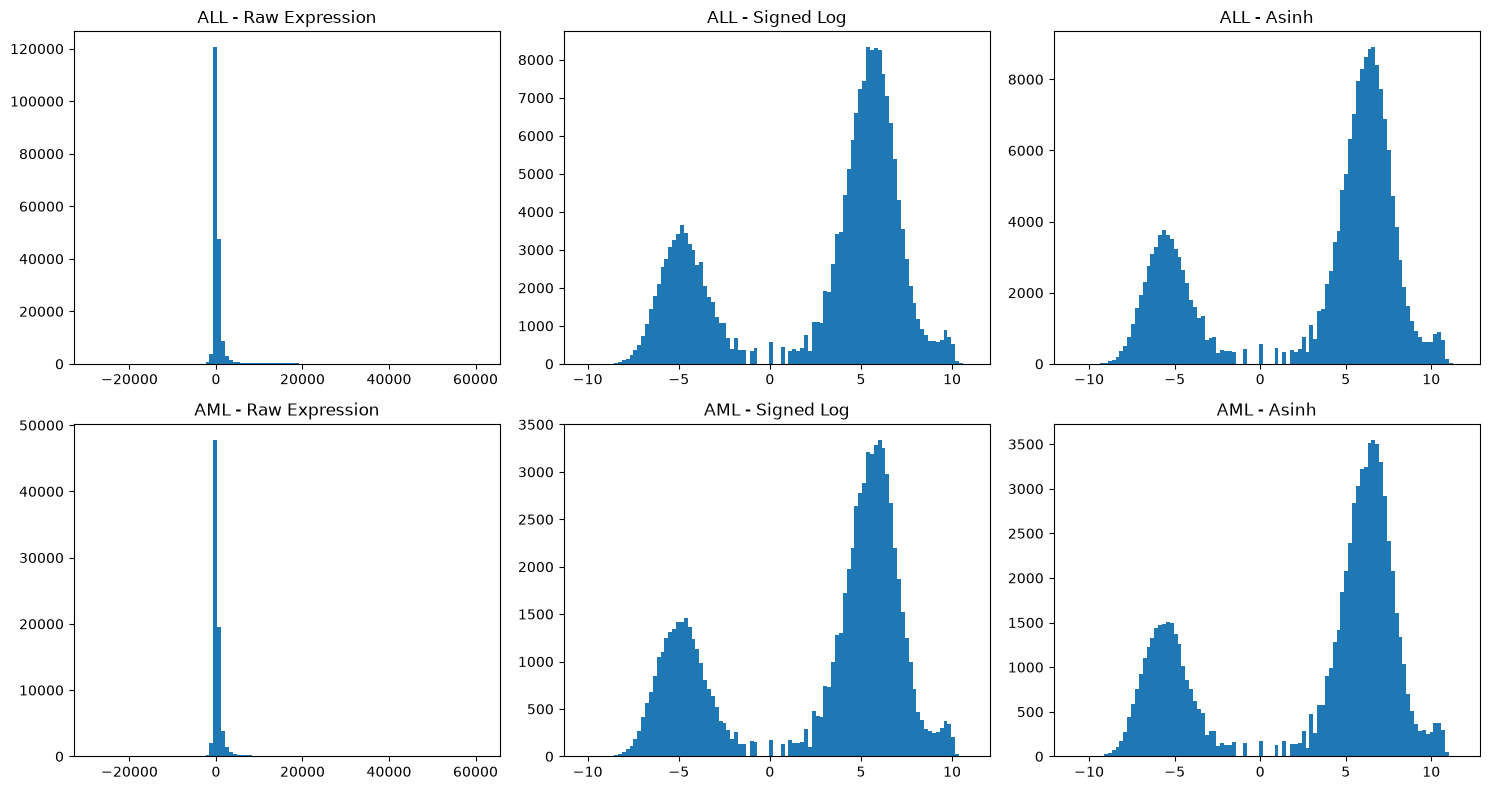

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

datasets = [
    (all_data, aml_data, "Raw Expression"),
    (all_log, aml_log, "Signed Log"),
    (all_asinh, aml_asinh, "Asinh")
]

for i, (all_data, aml_data, title) in enumerate(datasets):
    bins = np.histogram_bin_edges(
        np.concatenate([all_data.to_numpy().ravel(),
                        aml_data.to_numpy().ravel()]),
        bins=100
    )

    axes[0, i].hist(all_data.to_numpy().ravel(), bins=bins)
    axes[0, i].set_title(f"ALL - {title}")

    axes[1, i].hist(aml_data.to_numpy().ravel(), bins=bins)
    axes[1, i].set_title(f"AML - {title}")

plt.tight_layout()
plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

In [23]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
pc1_loadings = pd.Series(pca.components_[0], index=X_train.columns)

In [24]:
print(X_pca.shape)
print(pca.explained_variance_ratio_)
cumsum = np.cumsum(pca.explained_variance_ratio_)

(38, 38)
[1.49877930e-01 1.19778111e-01 6.60056806e-02 4.88492199e-02
 4.63241532e-02 3.72196529e-02 3.49097368e-02 3.28968370e-02
 2.98533570e-02 2.64532179e-02 2.50955698e-02 2.35785408e-02
 2.20532785e-02 2.08786432e-02 1.94178295e-02 1.89340717e-02
 1.84713718e-02 1.71329025e-02 1.70523096e-02 1.64475646e-02
 1.53558984e-02 1.52876881e-02 1.45609395e-02 1.43109079e-02
 1.41521484e-02 1.37856801e-02 1.34740603e-02 1.30587329e-02
 1.30315682e-02 1.24908759e-02 1.15991269e-02 1.11680809e-02
 1.03362895e-02 9.97974912e-03 9.23972538e-03 8.59086723e-03
 8.34768304e-03 2.95582098e-32]


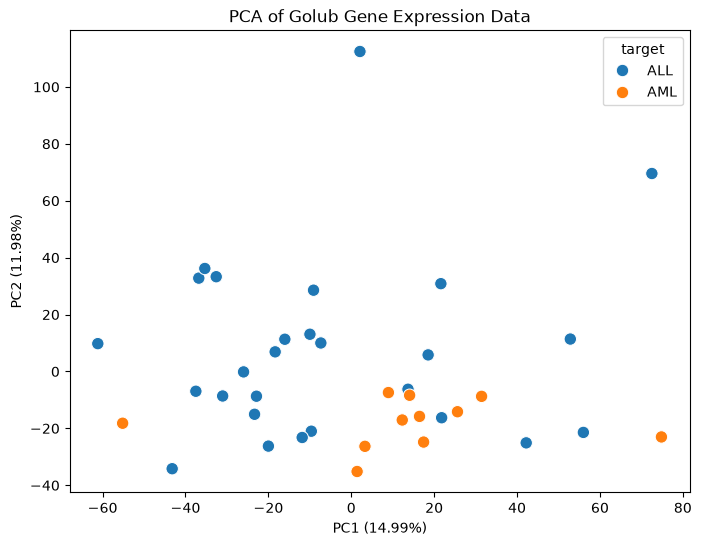

In [25]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel("PC1 (14.99%)")
plt.ylabel("PC2 (11.98%)")
plt.title("PCA of Golub Gene Expression Data")
plt.show()

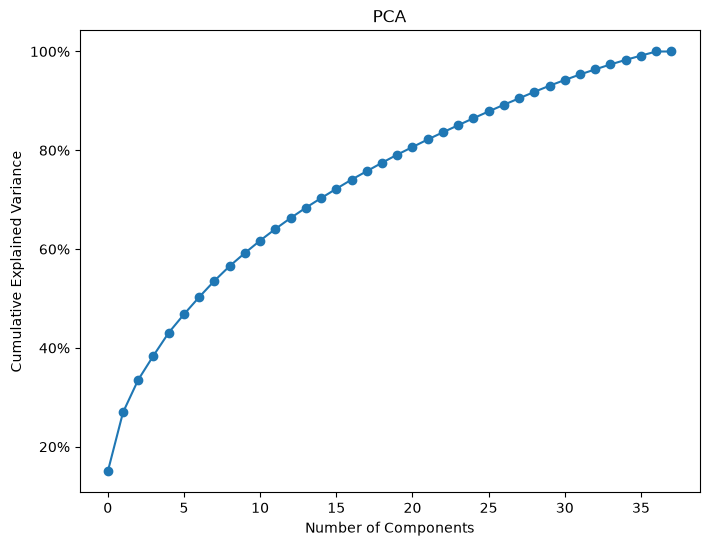

In [26]:
from matplotlib.ticker import PercentFormatter



line_plot = plt.figure(figsize=(8, 6))
plt.plot(cumsum, marker="o")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA")
plt.show()

In [27]:
print(np.where(cumsum >= 0.90)[0][0] + 1)

28


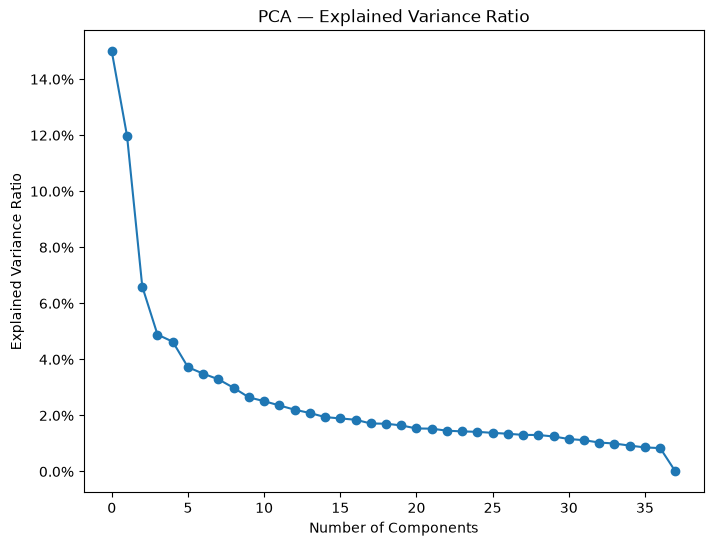

In [28]:
line_plot_vr = plt.figure(figsize=(8, 6))
plt.plot(pca.explained_variance_ratio_, marker="o")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Number of Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA — Explained Variance Ratio")
plt.show()

In [29]:
pc1_loadings.loc[pc1_loadings.abs().nlargest(10).index]

3835    0.029021
6337    0.028983
6136    0.028824
3838   -0.028757
4833   -0.028621
4636    0.028507
4131    0.028257
4691    0.028063
5047    0.027898
6454    0.027840
dtype: float64

In [41]:
from umap import UMAP

In [44]:
import umap

In [54]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [55]:
X_umap.shape

(38, 2)

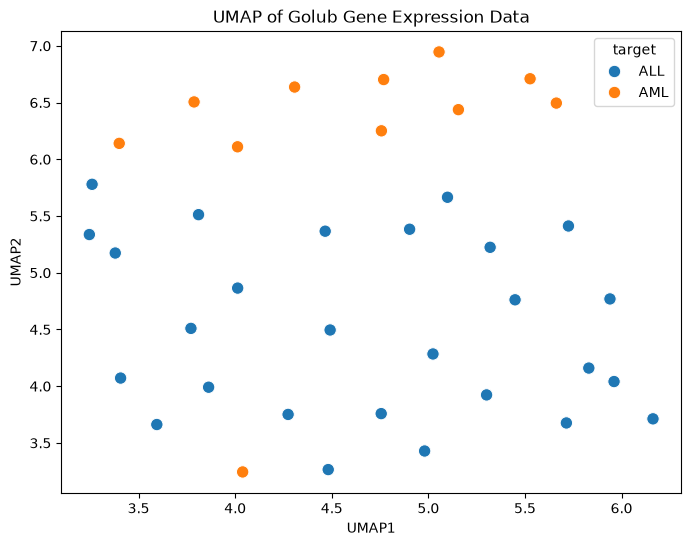

In [56]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_umap[:, 0],
    y=X_umap[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP of Golub Gene Expression Data")
plt.show()